## 1. Loading the Data

In [2]:
import pandas as pd

URL = "https://raw.githubusercontent.com/Swag-blips/project/refs/heads/main/member1_outputs/weather_clean.csv"
df = pd.read_csv(URL, parse_dates=["Date"])
print(df.shape)
df.head()

(142193, 26)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month,Year,split
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,1007.1,8.0,NaN,16.9,21.8,No,No,12,2008,train
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,1007.8,NaN,NaN,17.2,24.3,No,No,12,2008,train
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,1008.7,NaN,2.0,21.0,23.2,No,No,12,2008,test
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,1012.8,NaN,NaN,18.1,26.5,No,No,12,2008,train
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,1006.0,7.0,8.0,17.8,29.7,No,No,12,2008,train


## 2. Feature Setup and Chart 1: Rainy vs Dry Days

RainTomorrow
No     110316
Yes     31877
Name: count, dtype: int64


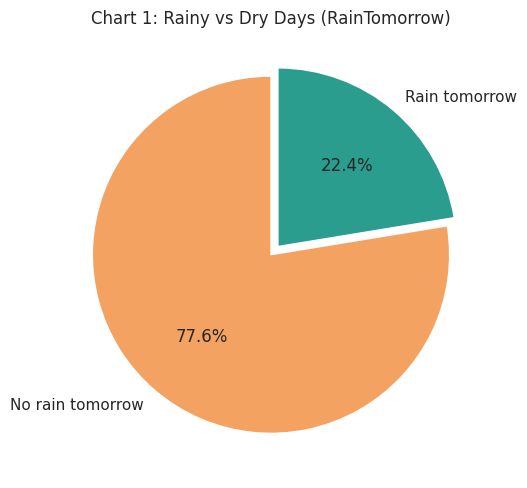

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Add the columns the charts need
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
season_map = {12: "Summer", 1: "Summer", 2: "Summer",
              3: "Autumn", 4: "Autumn", 5: "Autumn",
              6: "Winter", 7: "Winter", 8: "Winter",
              9: "Spring", 10: "Spring", 11: "Spring"}
df["Season"] = df["Month"].map(season_map)

# Chart 1: Rainy vs dry days
counts = df["RainTomorrow"].value_counts()
print(counts)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(counts, labels=["No rain tomorrow", "Rain tomorrow"],
       autopct="%1.1f%%", startangle=90, explode=(0, 0.06),
       colors=["#f4a261", "#2a9d8f"], wedgeprops={"edgecolor": "white"})
ax.set_title("Chart 1: Rainy vs Dry Days (RainTomorrow)")
plt.tight_layout()
plt.savefig("chart1_pie.png", dpi=150)
plt.show()

### Insight: Rainy vs Dry Days
About 78% of days are followed by no rain, and only 22% by rain. Rain is the less common outcome, so a model can look accurate just by always guessing "no rain". That's why we judge the rain model on more than accuracy.

## 3. Chart 2: Predicting Maximum Temperature

Builds a regression model to predict a day's maximum temperature (`MaxTemp`) from `MinTemp`, `Humidity3pm`, `Sunshine` and `Pressure3pm`. Missing feature values are filled with the median for the same location and month, calculated from the training data only so the test data stays unseen. The data is split 80/20 into training and test sets. Two models are compared: Linear Regression (a simple, interpretable baseline) and Gradient Boosting (which can capture non-linear patterns). Accuracy is measured with R², RMSE and MAE. The plots show actual vs predicted temperatures, the residuals (errors), and the linear model's coefficients, which show how each feature relates to MaxTemp.

                      R2   RMSE    MAE
Linear Regression  0.815  3.069  2.406
Gradient Boosting  0.849  2.767  2.128


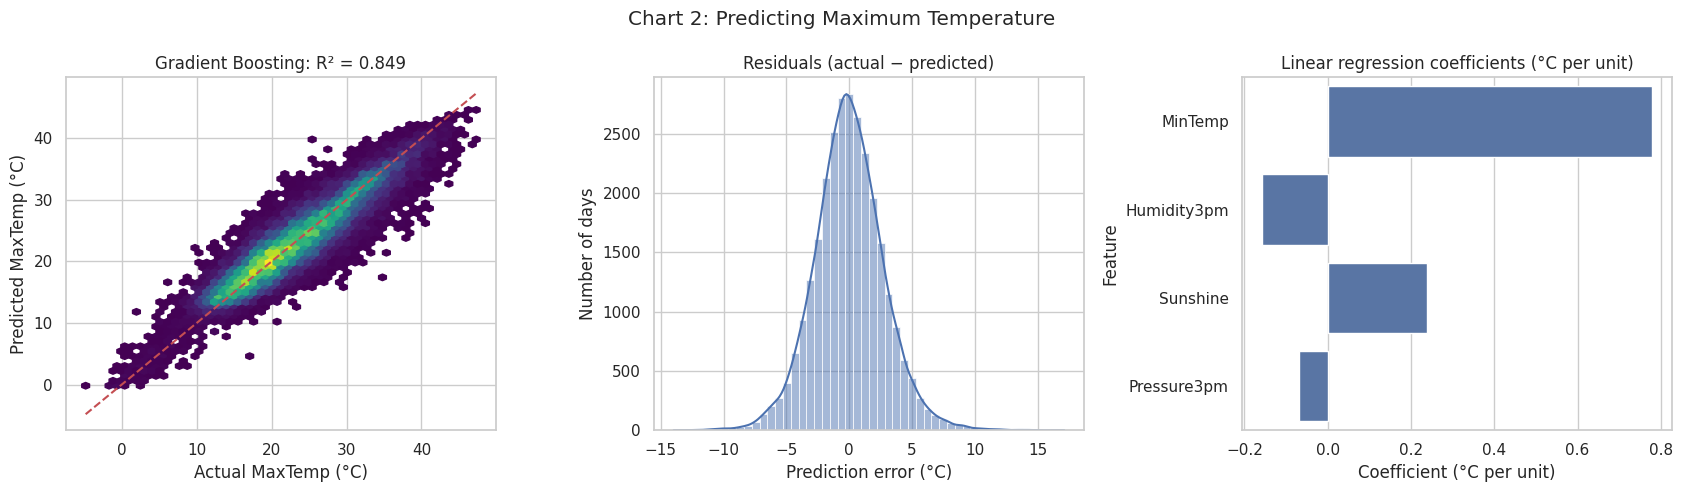

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

feats = ["MinTemp", "Humidity3pm", "Sunshine", "Pressure3pm"]
reg = df.dropna(subset=["MaxTemp"]).copy()
tr, te = train_test_split(reg, test_size=0.2, random_state=42)

# Impute by Location + Month (medians learned from the training set only)
loc_med = tr.groupby(["Location", "Month"])[feats].median().reset_index()
glob_med = tr[feats].median()

def impute(d):
    d = d.copy()
    m = d[["Location", "Month"]].merge(loc_med, on=["Location", "Month"], how="left")
    for f in feats:
        d[f] = d[f].fillna(pd.Series(m[f].values, index=d.index)).fillna(glob_med[f])
    return d

tr, te = impute(tr), impute(te)

models = {"Linear Regression": LinearRegression(),
          "Gradient Boosting": HistGradientBoostingRegressor(random_state=42)}
results, preds = {}, {}
for name, m in models.items():
    m.fit(tr[feats], tr["MaxTemp"])
    p = m.predict(te[feats])
    preds[name] = p
    results[name] = {"R2": r2_score(te["MaxTemp"], p),
                     "RMSE": mean_squared_error(te["MaxTemp"], p) ** 0.5,
                     "MAE": mean_absolute_error(te["MaxTemp"], p)}
print(pd.DataFrame(results).T.round(3))

best = max(results, key=lambda k: results[k]["R2"])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Panel 1: actual vs predicted
axes[0].hexbin(te["MaxTemp"], preds[best], gridsize=50, cmap="viridis", mincnt=1)
lims = [te["MaxTemp"].min(), te["MaxTemp"].max()]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual MaxTemp (°C)")
axes[0].set_ylabel("Predicted MaxTemp (°C)")
axes[0].set_title(f"{best}: R² = {results[best]['R2']:.3f}")

# Panel 2: residuals
sns.histplot(te["MaxTemp"] - preds[best], bins=50, kde=True, ax=axes[1])
axes[1].set_title("Residuals (actual − predicted)")
axes[1].set_xlabel("Prediction error (°C)")
axes[1].set_ylabel("Number of days")

# Panel 3: linear regression coefficients
coef = pd.Series(models["Linear Regression"].coef_, index=feats)
sns.barplot(x=coef.values, y=coef.index, ax=axes[2])
axes[2].set_title("Linear regression coefficients (°C per unit)")
axes[2].set_xlabel("Coefficient (°C per unit)")
axes[2].set_ylabel("Feature")

fig.suptitle("Chart 2: Predicting Maximum Temperature")
plt.tight_layout()
plt.savefig("chart2_regression.png", dpi=150)
plt.show()

### Insight: Predicting Maximum Temperature
We predicted a day's highest temperature using the minimum temperature, sunshine, humidity and air pressure. The model is usually off by only about 2-3°C, and its mistakes are balanced (not consistently too high or too low). Warmer nights (MinTemp) and more sunshine mean a hotter day, while higher humidity means a slightly cooler one. Gradient Boosting was a little more accurate than Linear Regression (R² 0.85 vs 0.81).

## 4. Chart 3: Average Annual Rainfall by Location

Calculates the average annual rainfall (mm) for each of the 49 locations and adds each location's latitude and longitude. Annual rainfall is estimated as the mean daily rainfall × 365, which keeps stations comparable even though some have missing days or partial years. The results are shown in two ways: a sorted horizontal bar chart (easy to rank and compare locations) and a map of Australia where bubble size and colour show rainfall (easy to see geographic patterns, such as the wet tropical north and east coast vs the dry interior).

        Location  AnnualRainfall_mm   lat    lon
8         Cairns             2104.0 -17.0  146.0
13        Darwin             1859.0 -12.0  131.0
11  CoffsHarbour             1845.0 -30.0  153.0
14     GoldCoast             1361.0 -28.0  153.0
47    Wollongong             1310.0 -34.0  151.0
        Location  AnnualRainfall_mm   lat    lon
48       Woomera              179.0 -31.0  137.0
41         Uluru              258.0 -25.0  131.0
3   AliceSprings              317.0 -24.0  134.0
25          Nhil              341.0 -36.0  142.0
20       Mildura              345.0 -34.0  142.0


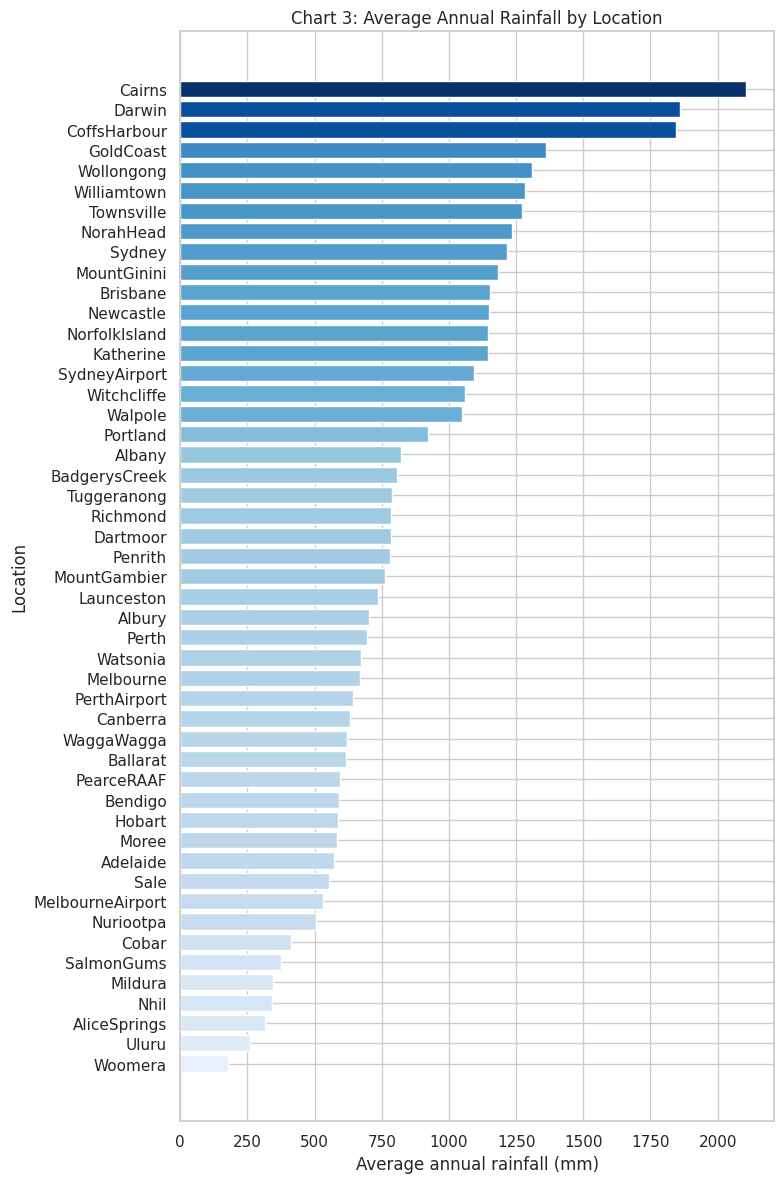

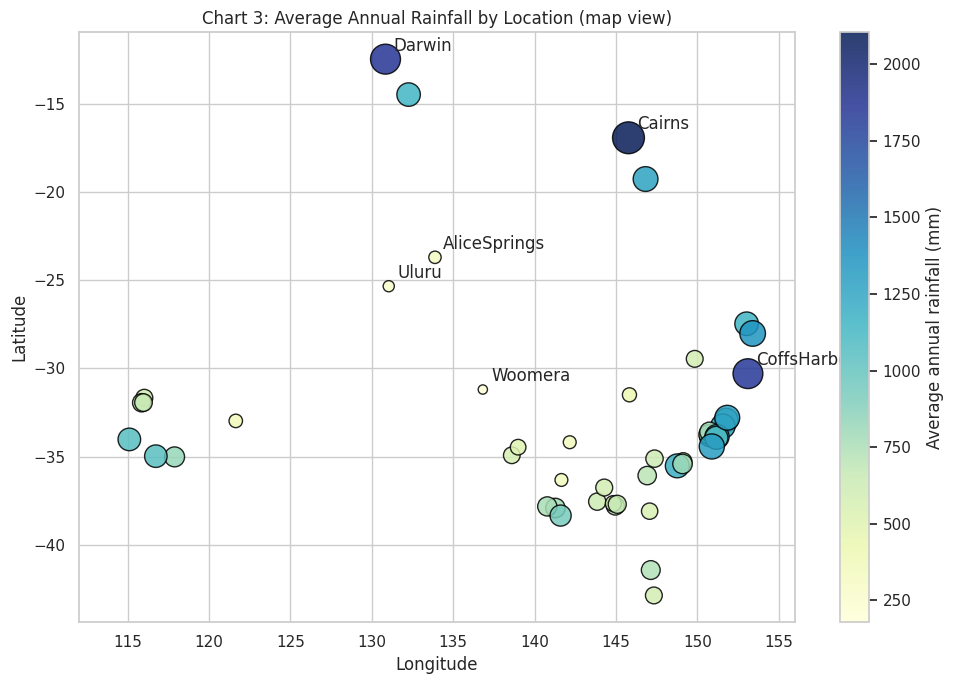

In [5]:
coords = {  # approximate (lat, lon) of each station
 "Albury": (-36.08,146.92), "BadgerysCreek": (-33.88,150.74), "Cobar": (-31.50,145.83),
 "CoffsHarbour": (-30.30,153.11), "Moree": (-29.46,149.84), "Newcastle": (-32.93,151.78),
 "NorahHead": (-33.28,151.57), "NorfolkIsland": (-29.04,167.95), "Penrith": (-33.75,150.69),
 "Richmond": (-33.60,150.75), "Sydney": (-33.87,151.21), "SydneyAirport": (-33.94,151.17),
 "WaggaWagga": (-35.12,147.37), "Williamtown": (-32.80,151.84), "Wollongong": (-34.43,150.89),
 "Canberra": (-35.28,149.13), "Tuggeranong": (-35.42,149.09), "MountGinini": (-35.53,148.77),
 "Ballarat": (-37.56,143.85), "Bendigo": (-36.76,144.28), "Sale": (-38.10,147.07),
 "MelbourneAirport": (-37.67,144.84), "Melbourne": (-37.81,144.96), "Mildura": (-34.19,142.16),
 "Nhil": (-36.33,141.65), "Portland": (-38.35,141.60), "Watsonia": (-37.71,145.08),
 "Dartmoor": (-37.92,141.28), "Brisbane": (-27.47,153.03), "Cairns": (-16.92,145.77),
 "GoldCoast": (-28.02,153.40), "Townsville": (-19.26,146.82), "Adelaide": (-34.93,138.60),
 "MountGambier": (-37.83,140.78), "Nuriootpa": (-34.47,138.99), "Woomera": (-31.20,136.82),
 "Albany": (-35.02,117.88), "Witchcliffe": (-34.03,115.10), "PearceRAAF": (-31.67,116.02),
 "PerthAirport": (-31.94,115.97), "Perth": (-31.95,115.86), "SalmonGums": (-32.98,121.64),
 "Walpole": (-34.98,116.73), "Hobart": (-42.88,147.33), "Launceston": (-41.44,147.14),
 "AliceSprings": (-23.70,133.88), "Darwin": (-12.46,130.84), "Katherine": (-14.47,132.26),
 "Uluru": (-25.34,131.04)}

# Average annual rainfall = mean daily rainfall x 365
annual = (df.groupby("Location")["Rainfall"].mean() * 365).rename("AnnualRainfall_mm").reset_index()
annual["lat"] = annual["Location"].map(lambda l: coords[l][0])
annual["lon"] = annual["Location"].map(lambda l: coords[l][1])
print(annual.sort_values("AnnualRainfall_mm", ascending=False).head(5).round(0))
print(annual.sort_values("AnnualRainfall_mm").head(5).round(0))

# Bar chart: ranking of all locations
a = annual.sort_values("AnnualRainfall_mm")
fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(a["Location"], a["AnnualRainfall_mm"],
        color=plt.cm.Blues(a["AnnualRainfall_mm"] / a["AnnualRainfall_mm"].max()))
ax.set_xlabel("Average annual rainfall (mm)")
ax.set_ylabel("Location")
ax.set_title("Chart 3: Average Annual Rainfall by Location")
plt.tight_layout()
plt.savefig("chart3_rainfall_bar.png", dpi=150)
plt.show()

# Simple location map: each dot is a station
fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(annual["lon"], annual["lat"],
                c=annual["AnnualRainfall_mm"], s=annual["AnnualRainfall_mm"] / 4,
                cmap="YlGnBu", edgecolor="black", alpha=0.85)
plt.colorbar(sc, label="Average annual rainfall (mm)")

# Label the 3 wettest and 3 driest locations
for _, r in pd.concat([annual.nlargest(3, "AnnualRainfall_mm"),
                       annual.nsmallest(3, "AnnualRainfall_mm")]).iterrows():
    ax.annotate(r["Location"], (r["lon"], r["lat"]), xytext=(6, 6), textcoords="offset points")

ax.set_xlim(112, 156)   # leaves out Norfolk Island, which sits far out in the Pacific
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Chart 3: Average Annual Rainfall by Location (map view)")
plt.tight_layout()
plt.savefig("chart3_rainfall_map.png", dpi=150)
plt.show()

### Insight: Rainfall Across Australia
Rainfall differs a lot between places. Cairns is the wettest at about 2,100 mm a year, while Woomera is the driest at about 180 mm, nearly 12 times less. The wet places are in the tropical north and along the east coast, and the dry places are in the inland desert.

## 5. Chart 4: Monthly Maximum Temperature Trends of 5 Major Cities

Tracks the average maximum temperature (`MaxTemp`) for each month in Sydney, Melbourne, Brisbane, Perth and Adelaide. The data is grouped by city and calendar month, then averaged, and each city is drawn as a line over the years. A line chart suits this because it shows how values change over time, so the yearly seasonal cycle and any long-term differences between cities are easy to compare.

           mean   min   max
Location                   
Adelaide   22.9  14.5  32.8
Brisbane   26.5  20.6  32.4
Melbourne  20.9  14.2  30.6
Perth      25.1  17.7  34.2
Sydney     23.0  17.1  29.6


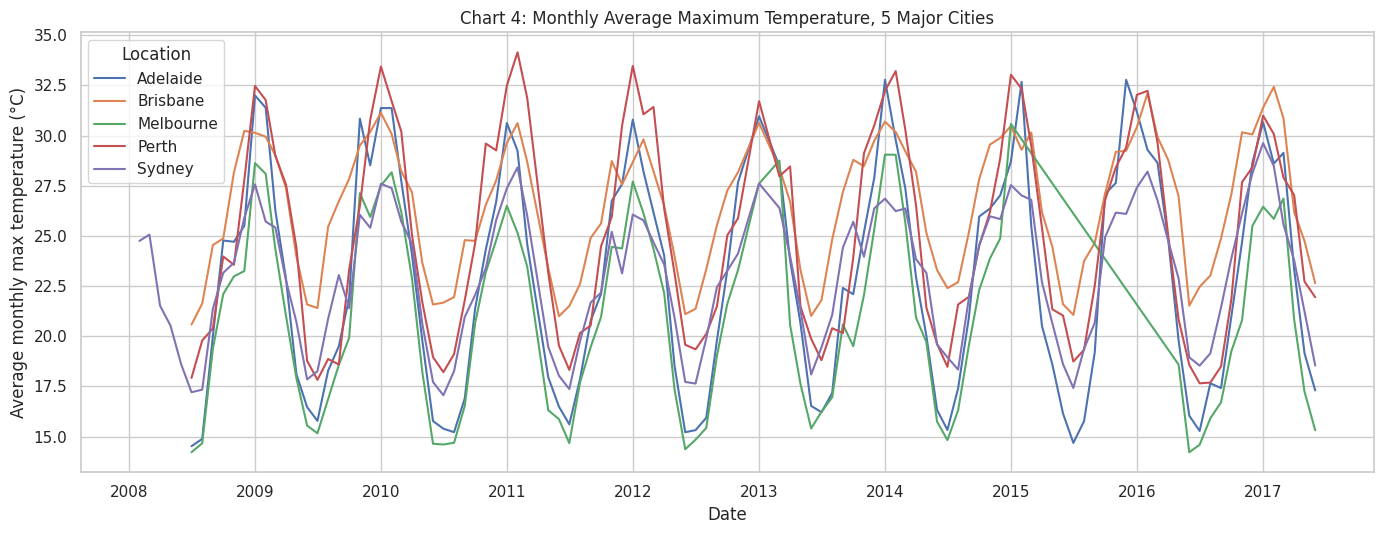

In [6]:
cities = ["Sydney", "Melbourne", "Brisbane", "Perth", "Adelaide"]
c5 = df[df["Location"].isin(cities)]

# Average max temperature per city per month (MS = month start)
monthly = (c5.groupby(["Location", pd.Grouper(key="Date", freq="MS")])["MaxTemp"]
             .mean().reset_index())
print(monthly.groupby("Location")["MaxTemp"].agg(["mean", "min", "max"]).round(1))

fig, ax = plt.subplots(figsize=(14, 5.5))
sns.lineplot(data=monthly, x="Date", y="MaxTemp", hue="Location", ax=ax)
ax.set_xlabel("Date")
ax.set_ylabel("Average monthly max temperature (°C)")
ax.set_title("Chart 4: Monthly Average Maximum Temperature, 5 Major Cities")
plt.tight_layout()
plt.savefig("chart4_temp_trends.png", dpi=150)
plt.show()

### Insight: Temperature Trends of 5 Major Cities
All five cities get hot in December-February and cooler in June-August, and the pattern repeats every year. Brisbane is the warmest overall, and Melbourne is the coolest. Adelaide has the biggest gap between summer and winter, while Sydney and Brisbane stay the most steady. Melbourne's line has a few gaps because some months are missing from its data.

## 6. Chart 5: Seasonal Rainfall of 5 Major Cities

Calculates the average daily rainfall (mm) in each season (Summer, Autumn, Winter, Spring) for Sydney, Melbourne, Brisbane, Perth and Adelaide, using Southern Hemisphere seasons. The data is grouped by city and season and averaged. A horizontal grouped bar chart is used so that the four seasons of each city sit side by side, making it easy to see which season is wettest in each city and to compare cities with each other.

Season     Summer  Autumn  Winter  Spring
Location                                 
Adelaide     0.95    1.63    2.56    1.13
Brisbane     5.39    3.52    1.60    2.37
Melbourne    1.70    1.64    1.70    2.27
Perth        0.61    1.60    3.73    1.57
Sydney       3.28    3.99    3.66    2.31


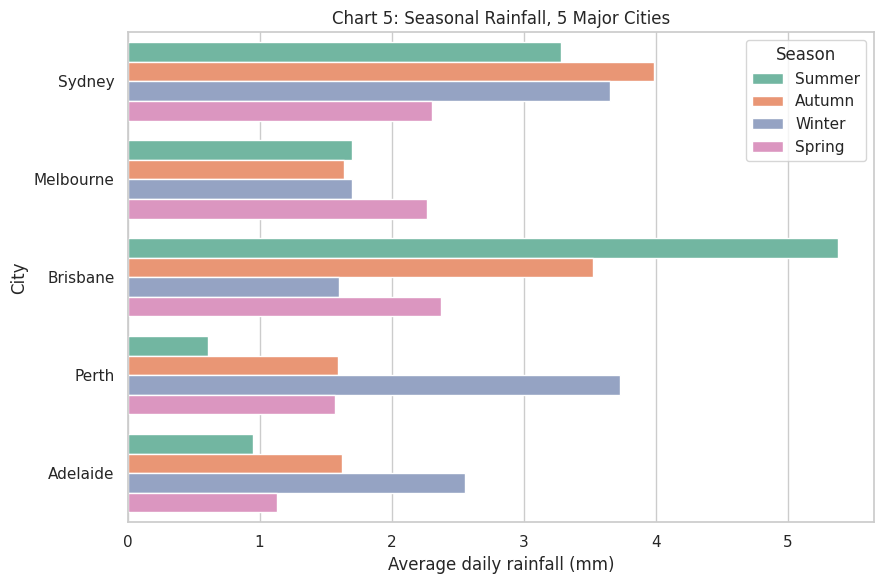

In [7]:
season_order = ["Summer", "Autumn", "Winter", "Spring"]

# Average daily rainfall per city per season (c5 and cities come from Chart 4)
seasonal = c5.groupby(["Location", "Season"])["Rainfall"].mean().reset_index()
print(seasonal.pivot(index="Location", columns="Season", values="Rainfall")[season_order].round(2))

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=seasonal, y="Location", x="Rainfall", hue="Season",
            hue_order=season_order, order=cities, orient="h",
            palette="Set2", ax=ax)
ax.set_xlabel("Average daily rainfall (mm)")
ax.set_ylabel("City")
ax.set_title("Chart 5: Seasonal Rainfall, 5 Major Cities")
plt.tight_layout()
plt.savefig("chart5_seasonal.png", dpi=150)
plt.show()

### Insight: Seasonal Rainfall of 5 Major Cities
Each city gets its rain at a different time of year. Brisbane is wettest in summer, while Perth and Adelaide are wettest in winter and very dry in summer. Sydney gets steady rain all year, and Melbourne is the most even across the seasons. So the "rainy season" depends on where you are.

## 7. Chart 6: Will It Rain Tomorrow?

Builds a classification model to predict `RainTomorrow` from the numeric weather features, using an 80/20 stratified split so both sets keep the same ~78/22 dry/rain ratio. Logistic Regression (a simple baseline) is compared with Gradient Boosting (which captures non-linear patterns). Because rainy days are the minority, both use balanced class weights and are judged on recall, F1 and ROC-AUC as well as accuracy. The plots show the confusion matrix, the ROC curves, and the most important features of the best model (permutation importance, which shows how much the score drops when a feature is shuffled).

(142193, 17)
['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'Month']
                     Accuracy  Precision  Recall     F1  ROC-AUC
Logistic Regression     0.789      0.520   0.767  0.620    0.865
Gradient Boosting       0.804      0.543   0.796  0.646    0.887
Best model: Gradient Boosting


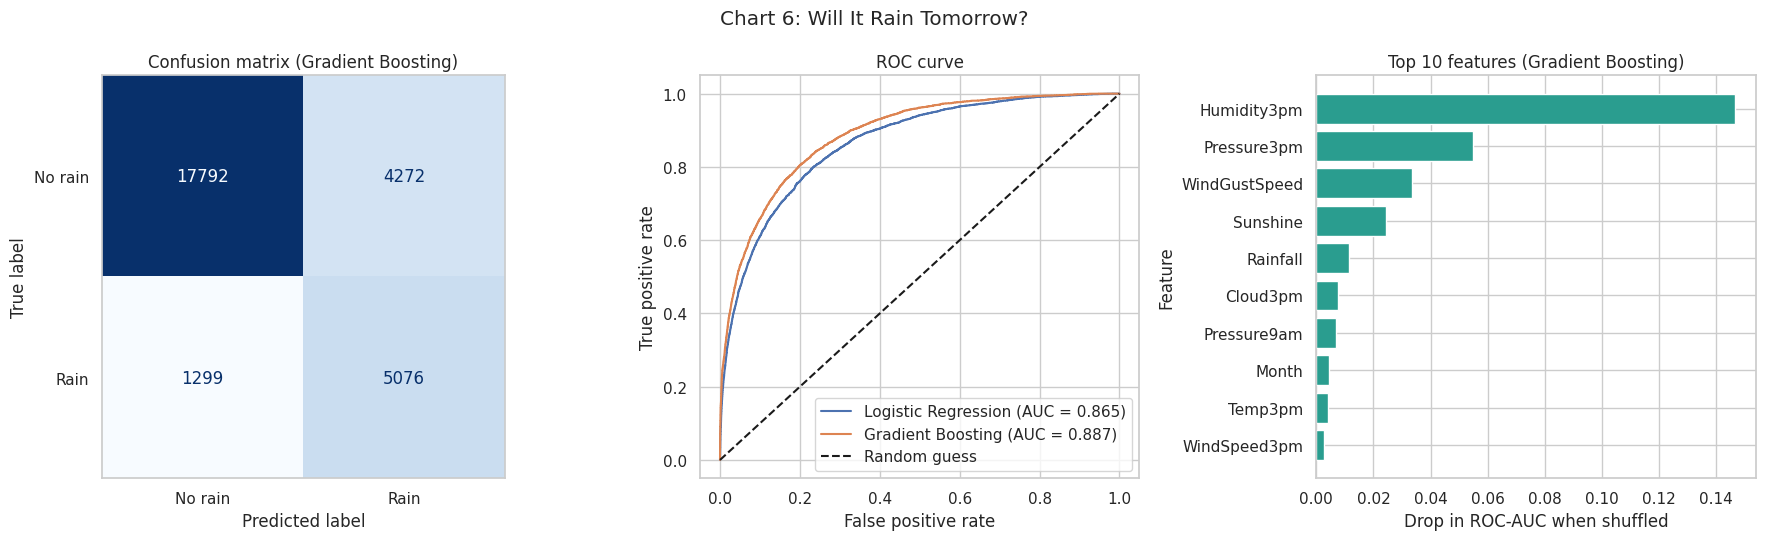

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

# Target as 0/1 (works whether the file stores Yes/No or 0/1)
y = df["RainTomorrow"]
if y.dtype == object:
    y = y.map({"Yes": 1, "No": 0})
y = y.astype(int)

# Features: all numeric / encoded columns except the target and Year (Year is a trend, not weather)
X = (df.select_dtypes(include=["number", "bool"])
       .drop(columns=["RainTomorrow", "Year"], errors="ignore")
       .astype(float))
print(X.shape)
print(list(X.columns))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
}

results, probas, preds = {}, {}, {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    yhat = (p >= 0.5).astype(int)
    probas[name], preds[name] = p, yhat
    results[name] = {"Accuracy": accuracy_score(y_te, yhat),
                     "Precision": precision_score(y_te, yhat),
                     "Recall": recall_score(y_te, yhat),
                     "F1": f1_score(y_te, yhat),
                     "ROC-AUC": roc_auc_score(y_te, p)}
print(pd.DataFrame(results).T.round(3))

best = max(results, key=lambda k: results[k]["ROC-AUC"])
print("Best model:", best)

# Permutation importance on a sample of the test set (keeps it fast)
samp = X_te.sample(min(10000, len(X_te)), random_state=42)
imp = permutation_importance(models[best], samp, y_te.loc[samp.index],
                             scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=X.columns).nlargest(10).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: confusion matrix
ConfusionMatrixDisplay.from_predictions(y_te, preds[best], display_labels=["No rain", "Rain"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix ({best})")
axes[0].grid(False)

# Panel 2: ROC curves
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve")
axes[1].legend(loc="lower right")

# Panel 3: most important features
axes[2].barh(imp_s.index, imp_s.values, color="#2a9d8f")
axes[2].set_xlabel("Drop in ROC-AUC when shuffled")
axes[2].set_ylabel("Feature")
axes[2].set_title(f"Top 10 features ({best})")

fig.suptitle("Chart 6: Will It Rain Tomorrow?")
plt.tight_layout()
plt.savefig("chart6_classification.png", dpi=150)
plt.show()

### Insight: Will It Rain Tomorrow?
Gradient Boosting predicted rain better than Logistic Regression (ROC-AUC 0.89 vs 0.87), so it was used as the main model. It catches about 80% of the rainy days, but only about 54% of its "rain" predictions are correct, which means it gives some false alarms. That is the trade-off of using balanced class weights, since missing real rain is the bigger problem for a rain forecast. The most important feature by far is the 3pm humidity, followed by 3pm air pressure and wind gust speed, which makes sense because humid air with falling pressure and strong gusts usually signals an approaching weather system.


## 8. Chart 7: Climate Zones

Groups the locations by their climate profile using K-Means clustering. Each location is summarised by five numbers: average temperature (mean of MinTemp and MaxTemp), average annual rainfall, humidity, sunshine and wind speed. These are standardised first so no single measure dominates the distance calculation. The number of clusters is chosen with the silhouette score (higher means better-separated groups). The results are shown on a map of Australia and on a temperature vs rainfall scatter plot, with a different colour and marker for each climate zone.

Missing values per feature:
 AvgTemp            0
AnnualRainfall     0
Humidity           0
Sunshine          19
Wind               0
{3: np.float64(0.308), 4: np.float64(0.308), 5: np.float64(0.298), 6: np.float64(0.305)}
Chosen k: 4
         AvgTemp  AnnualRainfall  Humidity  Sunshine  Wind
Cluster                                                   
0           14.3           717.4      65.1       7.0  25.3
1           19.1           467.1      47.0       8.5  24.0
2           21.6          1405.6      63.7       7.5  26.2
3           17.6           873.7      63.7       7.5  16.3
Cluster 0: Ballarat, Bendigo, Canberra, Dartmoor, Hobart, Launceston, Melbourne, MelbourneAirport, MountGambier, MountGinini, Nhil, Nuriootpa, Portland, Sale, Walpole, Watsonia, Witchcliffe
Cluster 1: Adelaide, AliceSprings, Cobar, Mildura, Moree, PearceRAAF, Perth, PerthAirport, SalmonGums, Uluru, WaggaWagga, Woomera
Cluster 2: Cairns, CoffsHarbour, Darwin, GoldCoast, Katherine, NorahHead, NorfolkIsland, Sy

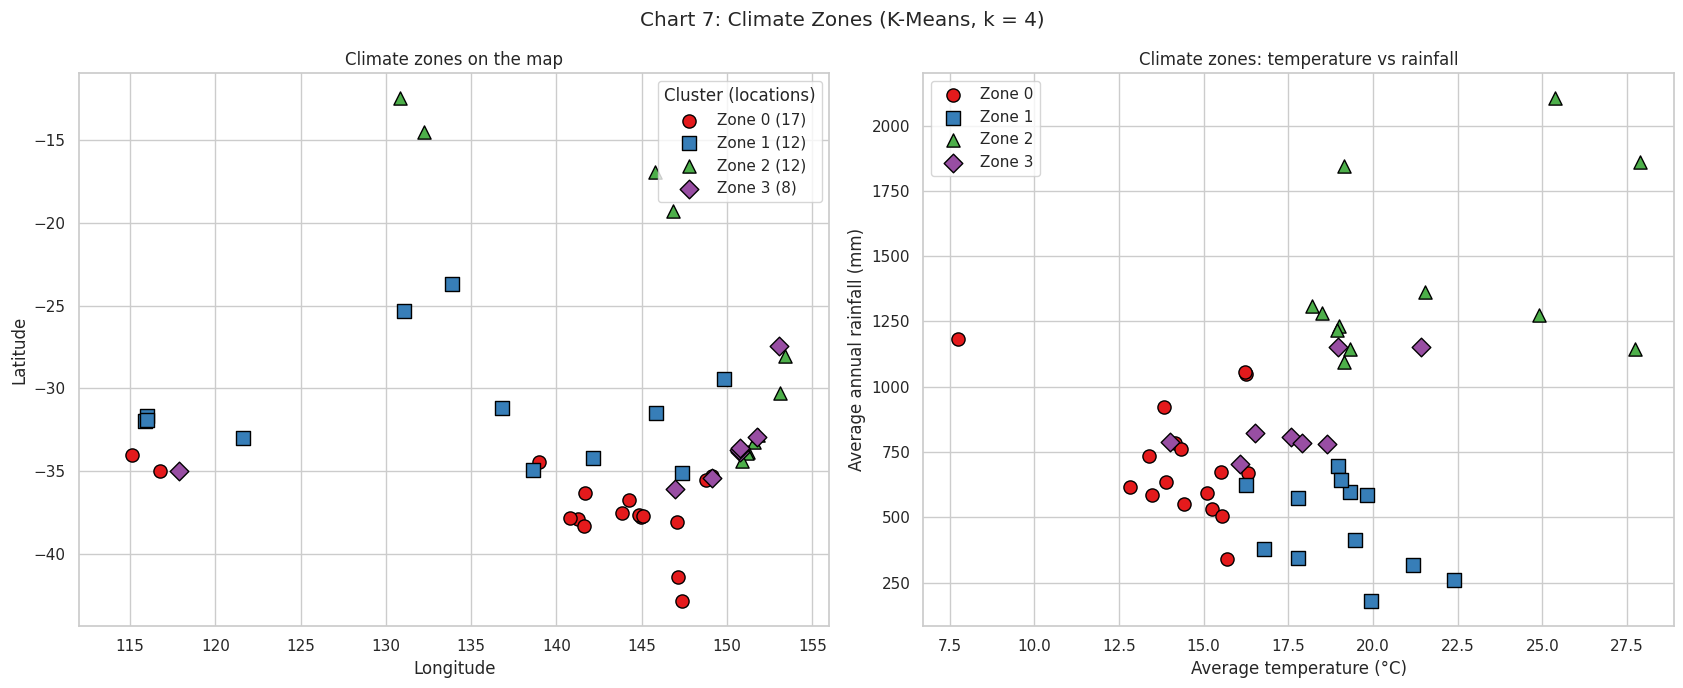

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wind_cols = [c for c in ["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"] if c in df.columns]
hum_cols = [c for c in ["Humidity9am", "Humidity3pm"] if c in df.columns]
loc = df["Location"]

# One row per location: its climate profile
prof = pd.DataFrame({
    "AvgTemp": ((df["MinTemp"] + df["MaxTemp"]) / 2).groupby(loc).mean(),
    "AnnualRainfall": annual.set_index("Location")["AnnualRainfall_mm"],
    "Humidity": df[hum_cols].mean(axis=1).groupby(loc).mean(),
    "Sunshine": df["Sunshine"].groupby(loc).mean(),
    "Wind": df[wind_cols].mean(axis=1).groupby(loc).mean(),
})
print("Missing values per feature:\n", prof.isna().sum().to_string())
prof = prof.fillna(prof.median())   # only matters if a location has no data for a measure

Z = StandardScaler().fit_transform(prof)

# Choose k (3-6 zones keeps the result interpretable) with the silhouette score
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=42).fit_predict(Z)) for k in range(3, 7)}
print({k: round(v, 3) for k, v in sil.items()})
k = max(sil, key=sil.get)
print("Chosen k:", k)

prof["Cluster"] = KMeans(k, n_init=10, random_state=42).fit_predict(Z)
prof["lat"] = prof.index.map(lambda l: coords[l][0])
prof["lon"] = prof.index.map(lambda l: coords[l][1])

# Cluster profile table (use it to name each zone) and members
print(prof.groupby("Cluster")[["AvgTemp", "AnnualRainfall", "Humidity", "Sunshine", "Wind"]].mean().round(1))
for c, g in prof.groupby("Cluster"):
    print(f"Cluster {c}:", ", ".join(g.index))

markers = ["o", "s", "^", "D", "P", "X"]
colors = sns.color_palette("Set1", k)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for c in range(k):
    g = prof[prof["Cluster"] == c]
    axes[0].scatter(g["lon"], g["lat"], s=90, marker=markers[c], color=colors[c],
                    edgecolor="black", label=f"Zone {c} ({len(g)})")
    axes[1].scatter(g["AvgTemp"], g["AnnualRainfall"], s=90, marker=markers[c], color=colors[c],
                    edgecolor="black", label=f"Zone {c}")
axes[0].set_xlim(112, 156)   # leaves out Norfolk Island (still clustered)
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_title("Climate zones on the map")
axes[0].legend(title="Cluster (locations)")
axes[1].set_xlabel("Average temperature (°C)")
axes[1].set_ylabel("Average annual rainfall (mm)")
axes[1].set_title("Climate zones: temperature vs rainfall")
axes[1].legend()

fig.suptitle("Chart 7: Climate Zones (K-Means, k = %d)" % k)
plt.tight_layout()
plt.savefig("chart7_climate_zones.png", dpi=150)
plt.show()

### Insight: Climate Zones
The 49 locations fall into 4 climate zones. One is cool and moderately wet in the south-east (Melbourne, Hobart, Canberra), one is dry, sunny and low in humidity (Alice Springs, Uluru, Woomera, Adelaide, Perth), one is the warmest and very wet along the tropical north and east coast (Cairns, Darwin, Sydney), and one is mild with the calmest winds (Brisbane, Albury, Penrith). The zones largely follow geography.

## 9. Chart 8: Wettest Location and Hottest Day

Highlights two records from the data in large "headline cards": the location with the highest average annual rainfall (from Chart 3) and the single hottest day recorded (the highest MaxTemp, with its location and date). Below each card, a small bar chart puts the record in context by showing the top 5 locations for that measure, with the record holder highlighted.

Location                  Cairns
AnnualRainfall_mm    2104.340756
Name: 8, dtype: object
Location                Woomera
Date        2011-01-25 00:00:00
MaxTemp                    48.1
Name: 103729, dtype: object


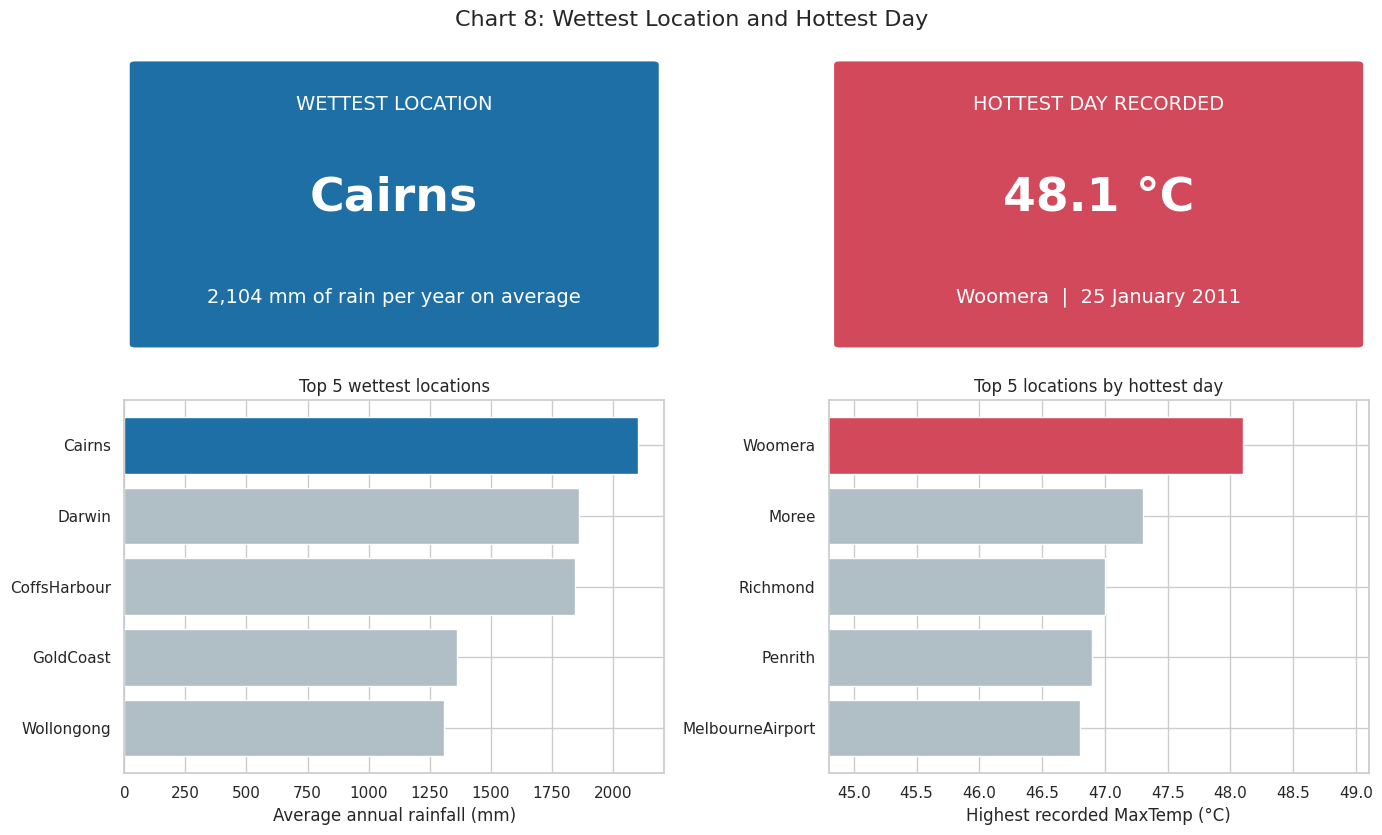

In [10]:
from matplotlib.patches import FancyBboxPatch

wet = annual.loc[annual["AnnualRainfall_mm"].idxmax()]
hot = df.loc[df["MaxTemp"].idxmax()]
print(wet[["Location", "AnnualRainfall_mm"]])
print(hot[["Location", "Date", "MaxTemp"]])

top_wet = annual.set_index("Location")["AnnualRainfall_mm"].nlargest(5).sort_values()
top_hot = df.groupby("Location")["MaxTemp"].max().nlargest(5).sort_values()

def card(ax, color, label, big, sub):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((0.02, 0.05), 0.96, 0.9, boxstyle="round,pad=0.01",
                                transform=ax.transAxes, facecolor=color, edgecolor="none"))
    ax.text(0.5, 0.82, label, ha="center", va="center", color="white", fontsize=14, transform=ax.transAxes)
    ax.text(0.5, 0.52, big, ha="center", va="center", color="white", fontsize=34,
            fontweight="bold", transform=ax.transAxes)
    ax.text(0.5, 0.2, sub, ha="center", va="center", color="white", fontsize=14, transform=ax.transAxes)

fig = plt.figure(figsize=(14, 8.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

card(fig.add_subplot(gs[0, 0]), "#1d6fa5", "WETTEST LOCATION",
     wet["Location"], f"{wet['AnnualRainfall_mm']:,.0f} mm of rain per year on average")
card(fig.add_subplot(gs[0, 1]), "#d1495b", "HOTTEST DAY RECORDED",
     f"{hot['MaxTemp']:.1f} °C", f"{hot['Location']}  |  {hot['Date'].strftime('%d %B %Y')}")

ax = fig.add_subplot(gs[1, 0])
ax.barh(top_wet.index, top_wet.values, color=["#b0bec5"] * 4 + ["#1d6fa5"])
ax.set_xlabel("Average annual rainfall (mm)")
ax.set_title("Top 5 wettest locations")

ax = fig.add_subplot(gs[1, 1])
ax.barh(top_hot.index, top_hot.values, color=["#b0bec5"] * 4 + ["#d1495b"])
ax.set_xlim(top_hot.min() - 2, top_hot.max() + 1)
ax.set_xlabel("Highest recorded MaxTemp (°C)")
ax.set_title("Top 5 locations by hottest day")

fig.suptitle("Chart 8: Wettest Location and Hottest Day", fontsize=16)
plt.tight_layout()
plt.savefig("chart8_records.png", dpi=150)
plt.show()

### Insight: Wettest Location and Hottest Day
Cairns is the wettest location, with about 2,100 mm of rain a year. The hottest day recorded was 48.1°C in Woomera on 25 January 2011. Both records come from opposite climates, a tropical coast and a desert interior, which matches the regional differences seen in the earlier charts.